<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%206/Latihan_Praktikum_6_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.16 Implementasi Python — KNN & Naive Bayes



## Praktikum 6.1 Persiapan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

## Praktikum 6.2 Import Dataset

In [2]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Ukuran data:", X.shape, "| distribusi kelas:", np.bincount(y))
X.head()

Ukuran data: (178, 13) | distribusi kelas: [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Praktikum 6.3 Preprocessing (Scaling untuk KNN)

In [3]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Catatan: Naive Bayes tidak memerlukan scaling,
# namun KNN sangat sensitif terhadap skala fitur.

## Praktikum 6.4 Training Model

In [4]:
knn = KNeighborsClassifier(n_neighbors=5, weights="distance")
knn.fit(X_train_scaled, y_train)

nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

## Praktikum 6.5 Evaluasi

In [5]:
acc_knn = accuracy_score(y_test, knn.predict(X_test_scaled))
acc_nb = accuracy_score(y_test, nb.predict(X_test))
print(f"Akurasi KNN (k=5, weighted): {acc_knn:.3f}")
print(f"Akurasi Gaussian Naive Bayes: {acc_nb:.3f}")

Akurasi KNN (k=5, weighted): 0.972
Akurasi Gaussian Naive Bayes: 0.972


## Praktikum 6.6 Visualisasi (Pengaruh Nilai k)

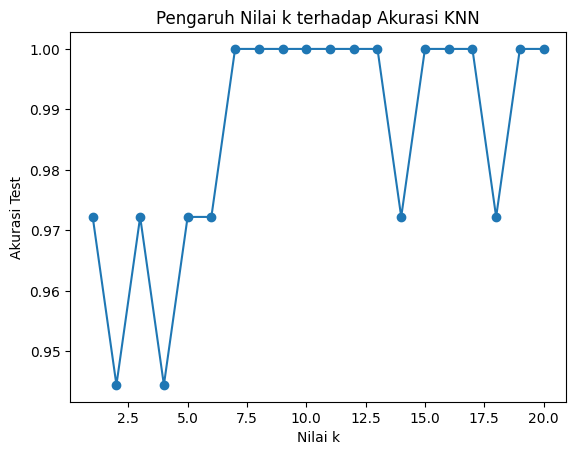

In [6]:
akurasi_k = []
nilai_k = range(1, 21)
for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    akurasi_k.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(nilai_k, akurasi_k, marker='o')
plt.xlabel("Nilai k"); plt.ylabel("Akurasi Test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.show()

### 6.16.1 Interpretasi — dan satu catatan penting

Pada split ini KNN (k=5) dan Gaussian NB sama-sama mencapai akurasi **0,972** (35 dari 36 data uji benar). Dataset Wine sudah mudah dipisahkan.

Buku menyebut pola *naik-turun* (akurasi rendah pada k sangat kecil, lalu turun lagi pada k sangat besar). Pada eksekusi ini **polanya tidak sejelas itu**: akurasi hanya bergerak antara 0,944 dan 1,000 sepanjang k = 1–20, dan tidak ada penurunan nyata pada k besar. Penyebabnya, test set hanya 36 sampel, sehingga satu sampel salah sudah menggeser akurasi ±0,028 (jadi fluktuasi bersifat acak, bukan tren). Itulah alasan buku menyarankan memilih k dengan **cross-validation**, yang kita lakukan di bawah.

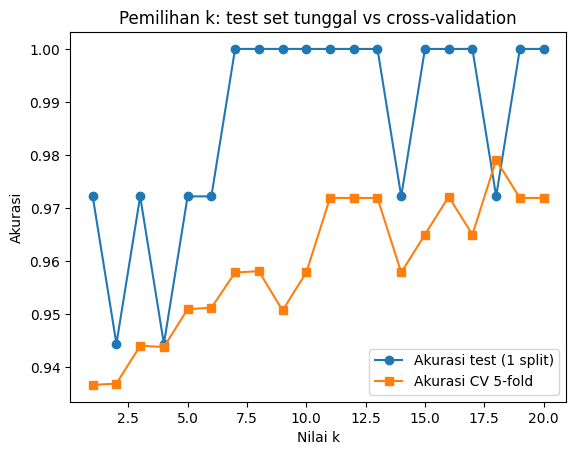

k terbaik menurut CV: 18 | akurasi CV: 0.979


In [7]:
# Pilih k dengan 5-fold cross-validation (hanya pada data latih)
from sklearn.model_selection import cross_val_score
cv_k = [cross_val_score(KNeighborsClassifier(n_neighbors=k),
                        X_train_scaled, y_train, cv=5).mean() for k in nilai_k]
plt.plot(nilai_k, akurasi_k, 'o-', label='Akurasi test (1 split)')
plt.plot(nilai_k, cv_k, 's-', label='Akurasi CV 5-fold')
plt.xlabel("Nilai k"); plt.ylabel("Akurasi"); plt.legend()
plt.title("Pemilihan k: test set tunggal vs cross-validation"); plt.show()
print("k terbaik menurut CV:", list(nilai_k)[int(np.argmax(cv_k))],
      "| akurasi CV:", round(max(cv_k), 3))

Kurva CV jauh lebih halus: naik dari ±0,94 (k=1–2) ke ±0,97–0,98 pada k sekitar 11–20, tanpa penurunan yang jelas. Jadi k kecil cenderung sedikit lebih rentan terhadap noise, tetapi underfitting pada k besar belum terlihat dalam rentang 1–20 untuk dataset ini.

---
## 6.17 Latihan Praktikum

### Praktikum 1: KNN vs Naive Bayes pada `load_breast_cancer`

Membandingkan **akurasi, waktu pelatihan, dan waktu prediksi** (modul `time`). Waktu diukur berulang (median dari 200 kali) agar tidak terpengaruh fluktuasi sesaat.

In [8]:
import time
import pandas as pd
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
print("Ukuran data:", Xb.shape, "| distribusi kelas:", np.bincount(yb))
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xb, yb, test_size=0.2, random_state=42, stratify=yb)

sc = StandardScaler()
Xb_tr_s = sc.fit_transform(Xb_tr)
Xb_te_s = sc.transform(Xb_te)

def ukur(fungsi, ulang=200):
    waktu = []
    for _ in range(ulang):
        mulai = time.perf_counter()
        fungsi()
        waktu.append(time.perf_counter() - mulai)
    return np.median(waktu)

knn_b = KNeighborsClassifier(n_neighbors=5, weights="distance")
nb_b = GaussianNB()

t_fit_knn = ukur(lambda: knn_b.fit(Xb_tr_s, yb_tr))
t_fit_nb  = ukur(lambda: nb_b.fit(Xb_tr, yb_tr))
t_pred_knn = ukur(lambda: knn_b.predict(Xb_te_s))
t_pred_nb  = ukur(lambda: nb_b.predict(Xb_te))

hasil = pd.DataFrame({
    "Akurasi": [accuracy_score(yb_te, knn_b.predict(Xb_te_s)),
                accuracy_score(yb_te, nb_b.predict(Xb_te))],
    "Waktu pelatihan (ms)": [t_fit_knn*1000, t_fit_nb*1000],
    "Waktu prediksi (ms)": [t_pred_knn*1000, t_pred_nb*1000],
}, index=["KNN (scaling, k=5)", "Gaussian NB"]).round(4)
display(hasil)

Ukuran data: (569, 30) | distribusi kelas: [212 357]


,Akurasi,Waktu pelatihan (ms),Waktu prediksi (ms)
"KNN (scaling, k=5)",0.9561,0.5244,1.1131
Gaussian NB,0.9386,0.9419,0.1959


In [9]:
# Tambahan: pengaruh scaling pada KNN & akurasi dengan cross-validation
knn_tanpa = KNeighborsClassifier(n_neighbors=5, weights="distance").fit(Xb_tr, yb_tr)
print("KNN TANPA scaling (test):", round(accuracy_score(yb_te, knn_tanpa.predict(Xb_te)), 3))
print("KNN dengan scaling (test):", round(accuracy_score(yb_te, knn_b.predict(Xb_te_s)), 3))
print("CV 5-fold KNN :", round(cross_val_score(KNeighborsClassifier(5, weights='distance'), Xb_tr_s, yb_tr, cv=5).mean(), 3))
print("CV 5-fold GNB :", round(cross_val_score(GaussianNB(), Xb_tr, yb_tr, cv=5).mean(), 3))

KNN TANPA scaling (test): 0.912
KNN dengan scaling (test): 0.956
CV 5-fold KNN : 0.967
CV 5-fold GNB : 0.936


#### Kesimpulan Praktikum 1

Hasil pada eksekusi saya (angka waktu akan sedikit berbeda di Colab, karena bergantung pada mesin):

| Model | Akurasi test | Akurasi CV 5-fold | Pelatihan | Prediksi |
|---|---|---|---|---|
| KNN (scaling, k=5) | 0,956 | 0,967 | ±0,3–0,5 ms | ±1 ms |
| Gaussian NB | 0,939 | 0,936 | ±1 ms | ±0,15–0,2 ms |

- **Akurasi:** KNN sedikit lebih tinggi (selisih 2 dari 114 data uji, dan konsisten di CV 0,967 vs 0,936). Namun KNN **bergantung pada scaling**: tanpa scaling akurasinya turun menjadi 0,912 (lebih rendah dari Naive Bayes), sedangkan Naive Bayes tidak butuh scaling.
- **Waktu prediksi:** Naive Bayes lebih cepat (±5–7×), sesuai teori. KNN adalah *lazy learner*: harus menghitung jarak ke seluruh data latih setiap kali memprediksi, sehingga makin lambat pada data besar.
- **Waktu pelatihan:** keduanya hanya berkisar milidetik pada data sekecil ini. KNN hampir tidak "melatih" (hanya menyimpan/mengindeks data), sedangkan Naive Bayes menghitung rata-rata dan varians per kelas. Urutan ini pada data kecil lebih dipengaruhi *overhead* pemanggilan daripada kompleksitas algoritma, jadi jangan dibaca sebagai selisih yang bermakna.
- **Ringkasnya:** KNN cocok bila akurasi diutamakan, data tidak terlalu besar, dan fitur sudah di-scaling. Naive Bayes unggul untuk prediksi cepat, data besar atau berdimensi tinggi, dan tanpa preprocessing.

### Praktikum 2: Klasifikasi Teks dengan Multinomial Naive Bayes (Praktikum 6.7)

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

teks = ["dapatkan diskon gratis sekarang",
        "rapat tim jam 10 pagi",
        "menangkan hadiah gratis klik disini",
        "laporan keuangan bulan ini", "diskon spesial hari ini",
        "jadwal kuliah minggu depan"]
label = [1, 0, 1, 0, 1, 0]  # 1 = spam, 0 = bukan spam

vectorizer = CountVectorizer()
X_teks = vectorizer.fit_transform(teks)
model = MultinomialNB(alpha=1.0)  # alpha = parameter Laplace Smoothing
model.fit(X_teks, label)

teks_baru = ["diskon gratis hari ini"]
prediksi = model.predict(vectorizer.transform(teks_baru))
print("Prediksi:",
      "Spam" if prediksi[0] == 1 else "Bukan Spam")

Prediksi: Spam


In [11]:
# Tambahan: kosakata, probabilitas, dan pengaruh alpha (Laplace smoothing)
print("Kosakata:", list(vectorizer.get_feature_names_out()))
print("Prior kelas [bukan spam, spam]:", np.exp(model.class_log_prior_).round(2))

uji = ["diskon gratis hari ini", "rapat laporan keuangan",
       "klik hadiah gratis sekarang", "jadwal rapat tim", "pulsa murah"]
tabel = {}
for a in [0.01, 1.0, 10.0]:
    m = MultinomialNB(alpha=a).fit(X_teks, label)
    tabel[f"P(spam), alpha={a}"] = m.predict_proba(vectorizer.transform(uji))[:, 1].round(3)
import pandas as pd
pd.DataFrame(tabel, index=uji)

Kosakata: ['10', 'bulan', 'dapatkan', 'depan', 'disini', 'diskon', 'gratis', 'hadiah', 'hari', 'ini', 'jadwal', 'jam', 'keuangan', 'klik', 'kuliah', 'laporan', 'menangkan', 'minggu', 'pagi', 'rapat', 'sekarang', 'spesial', 'tim']
Prior kelas [bukan spam, spam]: [0.5 0.5]


,"P(spam), alpha=0.01","P(spam), alpha=1.0","P(spam), alpha=10.0"
diskon gratis hari ini,1.0,0.947,0.613
rapat laporan keuangan,0.0,0.111,0.429
klik hadiah gratis sekarang,1.0,0.960,0.615
jadwal rapat tim,0.0,0.111,0.429
pulsa murah,0.5,0.500,0.500


#### Kesimpulan Praktikum 2

- Teks "diskon gratis hari ini" diprediksi **Spam** (probabilitas ±0,95 pada alpha=1). Kata "diskon", "gratis", dan "hari ini" lebih sering muncul pada contoh spam, sehingga likelihood kelas spam lebih besar.
- **Pipeline:** teks → `CountVectorizer` (bag-of-words, jumlah kemunculan kata) → `MultinomialNB`, yang cocok untuk data cacah/frekuensi kata.
- **Peran alpha (Laplace smoothing):** alpha mencegah probabilitas nol untuk kata yang tidak pernah muncul pada suatu kelas. Alpha kecil (0,01) membuat model sangat yakin (probabilitas ekstrem 0/1), alpha besar (10) membuat probabilitas mendekati 0,5 karena data terlalu "dihaluskan".
- **Kata di luar kosakata** diabaikan: "pulsa murah" tidak mengandung kata yang dikenal, sehingga probabilitasnya hanya mengikuti prior (0,5) dan hasilnya tidak bermakna.
- **Keterbatasan:** hanya 6 contoh latih, jadi ini hanya demonstrasi konsep. Untuk kasus nyata dibutuhkan ribuan teks, preprocessing (lowercase, stopword, stemming bahasa Indonesia), dan evaluasi pada data uji terpisah.